# Stream B: Reference Adaptation Strategies and Hindsight Oracles

**Master's Thesis Project:** Seasonality-Aware Drift Detection System  
**Stream B:** base forecasting model, action catalog, reference strategies (do nothing, always retrain, scheduled retraining), hindsight oracles and the MASE gain with a block bootstrap interval.

The results are computed by `python -m src.recommendations.run_backtest` (about 40 minutes on 16 cores) and read here from `data/processed/stream_b/`.

In [1]:
# Import required libraries
import sys
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Adds the parent directory (project root) to the Python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.recommendations.backtester import STRATEGIES
from src.recommendations.catalog import CATALOG
from src.recommendations.plots import plot_example, plot_quality_cost

RESULTS = "../data/processed/stream_b"
runs = pd.read_csv(f"{RESULTS}/runs.csv")
summary = pd.read_csv(f"{RESULTS}/summary.csv")
picks = pd.read_csv(f"{RESULTS}/oracle_picks.csv")

series = runs.drop_duplicates(["source", "series", "scenario"])
print(f"Series: {len(series)}")
print(series.groupby(["source", "scenario"]).size().to_string())

Series: 263
source     scenario     
entsoe     lockdown_2020     8
seismic    lockdown_2020    15
synthetic  level_shift      60
           none             60
           trend_ramp       60
           variance         60


## 1. Action Catalog and Strategies

Every action is a complete, executable recipe: the LLM will choose an action by name, and the backtest can apply and measure any of them. A strategy decides when an action is applied.

In [2]:
display(pd.DataFrame([(a.name, a.title_en, a.kind) for a in CATALOG], columns=["action", "description", "kind"]))
display(pd.DataFrame([(s.name, s.cadence_days, s.policy, s.action) for s in STRATEGIES],
                     columns=["strategy", "decision every N days", "policy", "action"]))

,action,description,kind
0,keep,do nothing,none
1,retrain_full,retrain on all history,retrain
2,retrain_8w,retrain on the last 8 weeks,retrain
3,retrain_2w,shorten the training window to 2 weeks,retrain
4,reweight_1w,reweight recent data (weight half-life 1 week),retrain
5,add_profile,add a seasonal feature: 4-week hour-of-week pr...,retrain
6,recalibrate_level,recalibrate the forecast level on the last week,recalibrate


,strategy,decision every N days,policy,action
0,nothing,NaN,fixed,None
1,always,1.0,fixed,retrain_full
2,scheduled,7.0,fixed,retrain_full
3,oracle_weekly,7.0,oracle,None
4,oracle,1.0,oracle,None


## 2. Base Model Validation

LightGBM settings were chosen on validation windows that do not overlap the test runs: other control seeds of the synthetic series and autumn 2019 for ENTSO-E (the test period is 2020). A static model trained at deployment, MASE on the following weeks (`run_backtest --tune`).

In [3]:
tune = pd.read_csv(f"{RESULTS}/tune.csv")
tune.groupby(["source", "config"]).agg(mase=("mase", "mean"), mase_naive=("mase_naive", "mean"),
                                     series=("series", "nunique")).round(3)

mase  mase_naive  series
source    config                                                      
entsoe    A: 200 rounds, lr 0.05, 31 leaves  0.486       0.806       8
          B: 400 rounds, lr 0.05, 63 leaves  0.481       0.806       8
          C: 300 rounds, lr 0.03, 15 leaves  0.512       0.806       8
          D: 200 rounds, lr 0.10, 31 leaves  0.498       0.806       8
synthetic A: 200 rounds, lr 0.05, 31 leaves  0.945       1.040      40
          B: 400 rounds, lr 0.05, 63 leaves  0.967       1.040      40
          C: 300 rounds, lr 0.03, 15 leaves  0.933       1.040      40
          D: 200 rounds, lr 0.10, 31 leaves  0.973       1.040      40

## 3. Quality Against Cost

Mean over series per source, scenario and strategy. MASE is scaled by the weekly seasonal naive error on the training data. `regret` = MASE after the change minus the ideal oracle's. `retrains` counts deployed retrainings (for the oracles: the chosen actions, not the trial fits). `gain_vs_nothing` = MASE(do nothing) - MASE(strategy) after the change; `share_gain_significant` = share of series where the lower bound of the 95% moving block bootstrap interval of the gain is above 0.

In [4]:
summary.round(3)

,source,scenario,strategy,series,mase_pre,mase_post,regret,retrains,gain_vs_nothing,share_gain_significant
0,entsoe,lockdown_2020,naive,8,0.976,1.025,0.539,0.000,-0.238,0.000
1,entsoe,lockdown_2020,nothing,8,0.546,0.787,0.301,0.000,NaN,NaN
2,entsoe,lockdown_2020,always,8,0.543,0.650,0.164,174.000,0.137,0.750
3,entsoe,lockdown_2020,scheduled,8,0.546,0.696,0.209,24.000,0.092,0.625
4,entsoe,lockdown_2020,oracle_weekly,8,0.525,0.607,0.121,17.500,0.180,1.000
5,entsoe,lockdown_2020,oracle,8,0.451,0.486,0.000,139.125,0.301,1.000
6,seismic,lockdown_2020,naive,15,0.846,1.112,0.355,0.000,0.337,0.333
7,seismic,lockdown_2020,nothing,15,0.806,1.449,0.693,0.000,NaN,NaN
8,seismic,lockdown_2020,always,15,0.754,0.921,0.165,83.000,0.528,0.867
9,seismic,lockdown_2020,scheduled,15,0.779,0.998,0.241,11.000,0.452,0.800


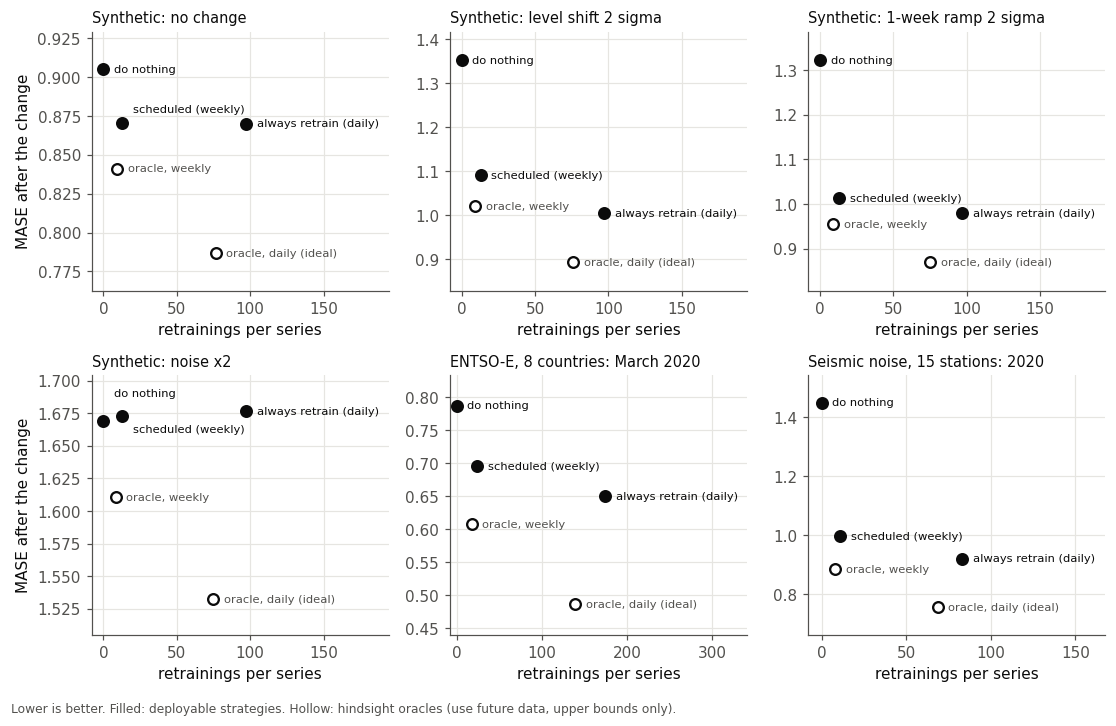

In [5]:
fig = plot_quality_cost(summary[summary.strategy != "naive"])
plt.show()

## 4. Actions Chosen by the Oracles

Share of decisions in which each oracle chose each catalog action.

In [6]:
picks

,strategy,source,scenario,decisions,keep,retrain_full,retrain_8w,retrain_2w,reweight_1w,add_profile,recalibrate_level
0,oracle_weekly,entsoe,lockdown_2020,192,0.15,0.24,0.06,0.05,0.06,0.32,0.12
1,oracle,entsoe,lockdown_2020,1392,0.09,0.18,0.12,0.12,0.16,0.22,0.11
2,oracle_weekly,seismic,lockdown_2020,165,0.16,0.22,0.09,0.12,0.13,0.17,0.11
3,oracle,seismic,lockdown_2020,1245,0.08,0.19,0.14,0.17,0.15,0.18,0.10
4,oracle_weekly,synthetic,level_shift,780,0.09,0.20,0.07,0.04,0.07,0.31,0.21
5,oracle,synthetic,level_shift,5820,0.09,0.16,0.12,0.11,0.11,0.28,0.12
6,oracle_weekly,synthetic,none,780,0.14,0.27,0.05,0.01,0.03,0.36,0.13
7,oracle,synthetic,none,5820,0.10,0.21,0.11,0.08,0.10,0.30,0.11
8,oracle_weekly,synthetic,trend_ramp,780,0.11,0.21,0.06,0.03,0.05,0.34,0.20
9,oracle,synthetic,trend_ramp,5820,0.10,0.16,0.11,0.11,0.10,0.29,0.13


## 5. Examples

Day-ahead forecasts of three strategies around the change (top) and their daily MASE (bottom): the synthetic client with the largest seasonal amplitude, Portugal (national load) and Milan (seismic noise).

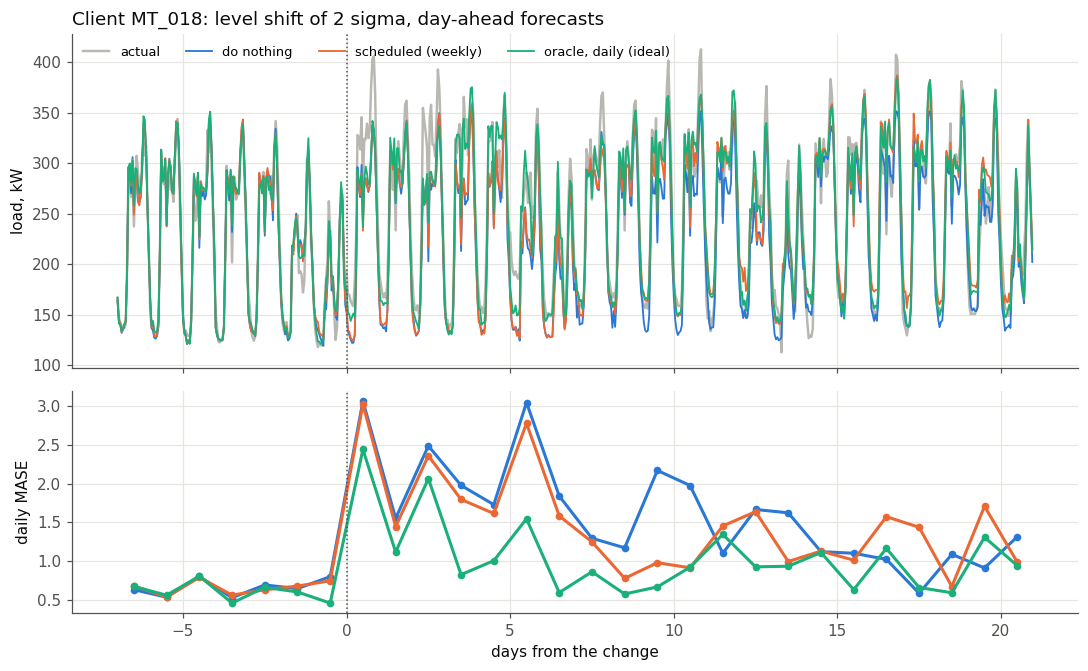

In [7]:
df = pd.read_csv(f"{RESULTS}/example_level_shift.csv")
fig = plot_example(df, f"Client {df.client.iloc[0]}: level shift of 2 sigma, day-ahead forecasts", "load, kW")
plt.show()

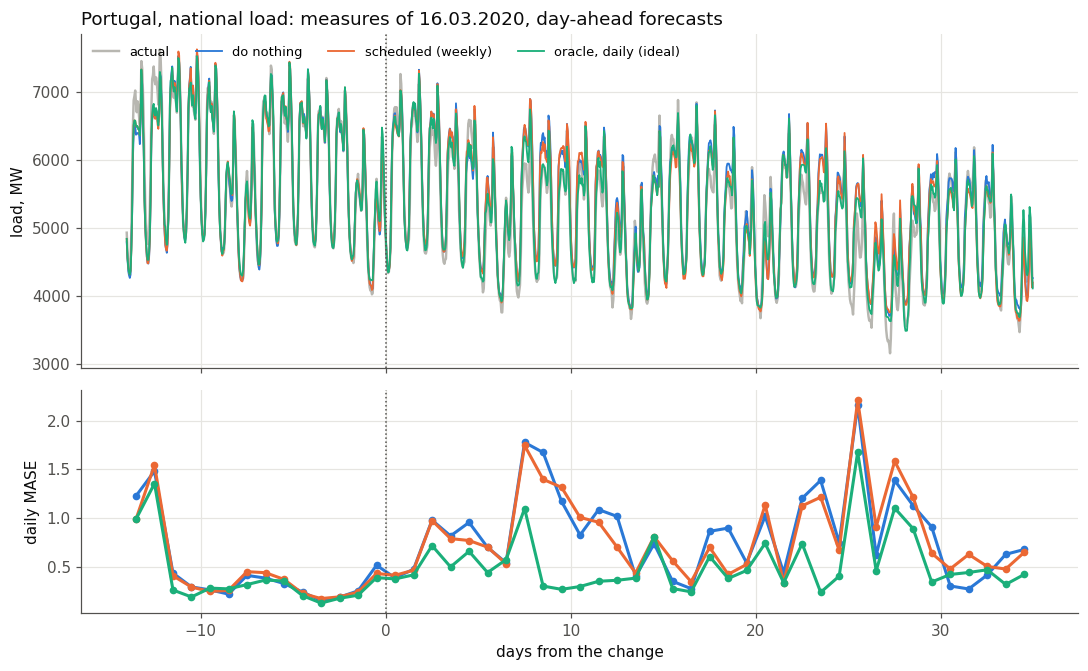

In [8]:
df = pd.read_csv(f"{RESULTS}/example_entsoe_PT.csv")
fig = plot_example(df, "Portugal, national load: measures of 16.03.2020, day-ahead forecasts", "load, MW")
plt.show()

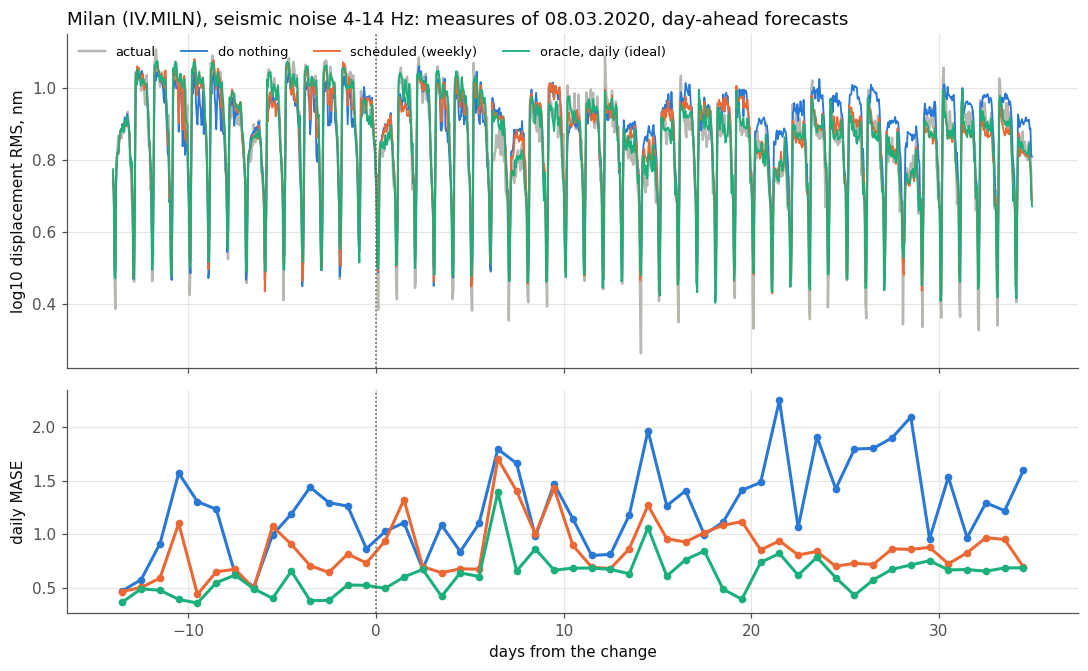

In [9]:
df = pd.read_csv(f"{RESULTS}/example_seismic_MILN.csv")
fig = plot_example(df, "Milan (IV.MILN), seismic noise 4-14 Hz: measures of 08.03.2020, day-ahead forecasts",
                   "log10 displacement RMS, nm")
plt.show()

## 6. Consistency Checks

By construction the weekly oracle can always choose `retrain_full`, which is what the scheduled strategy does, so on every series it is never worse than `scheduled`; the same holds for the daily oracle and `always`.

In [10]:
m = runs.pivot_table(index=["source", "series", "scenario"], columns="strategy", values="mase_all")
print(f"oracle_weekly <= scheduled on {(m.oracle_weekly <= m.scheduled + 1e-9).sum()} of {len(m)} series")
print(f"oracle <= always on {(m.oracle <= m.always + 1e-9).sum()} of {len(m)} series")

oracle_weekly <= scheduled on 263 of 263 series
oracle <= always on 263 of 263 series


## 7. Next Steps

- Decisions tied to detector alarms instead of the calendar: `BaselineDetectorWrapper.run` from Stream A returns the alarm indices that a strategy can react to.
- LLM recommendations (Instructor + Pydantic schema: an action from the catalog and its rationale), compared with `oracle_weekly` and the reference strategies.
- Acceptance rule: an action is accepted if the lower bound of the 95% bootstrap interval of the MASE gain is above a threshold delta.